<a href="https://colab.research.google.com/github/cupcake-7998/House-Price-Prediction-My-Homework-Project-/blob/main/house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## California House Price Prediction (My Homework Project!)

Hey everyone! For this project, I'm playing around with a few regression models to figure out which one does the best job predicting home prices in California.

Here's my game plan:
1. Get the dataset loaded and cleaned up.
2. Run a few simple baseline models just to see where we stand.
3. Take our best-performing model and tune it to squeeze out some extra performance.
4. Do a final check on the test set to see how we did!

*Quick heads up: The house values are stored in units of $100,000 (so a value of 2.5 means $250k).*

## 1. Getting Set Up

Let's kick things off by grabbing our imports and setting up the environment. You'll need an active internet connection since we are fetching the dataset on the fly.

In [ ]:
# Let's make sure we have all our modeling, plotting, and saving packages installed
%pip install -q scikit-learn pandas numpy matplotlib seaborn joblib

In [ ]:
# Creating a local pipeline.py to resolve imports and establish the modeling pipeline
with open('pipeline.py', 'w') as f:
    f.write('''
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge

RAW_FEATURES = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude"
]

def build_model_pipeline(estimator):
    # Simple preprocessor scaling features and handling any missing values
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), RAW_FEATURES)
        ]
    )
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

def get_candidate_models(random_state=42):
    return {
        "ridge": Ridge(random_state=random_state),
        "random_forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=random_state, n_jobs=-1),
        "hist_gradient_boosting": HistGradientBoostingRegressor(random_state=random_state)
    }

def build_tuned_model(random_state=42):
    return build_model_pipeline(HistGradientBoostingRegressor(random_state=random_state))
''')

In [ ]:
import sys
from pathlib import Path

# Ensure the current directory is first in sys.path to find our local pipeline.py
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

from pipeline import RAW_FEATURES, build_model_pipeline, get_candidate_models, build_tuned_model

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Taking a Quick Peek at the Data

Let's load up the California housing dataset from scikit-learn. I'll print out its shape, look at some basic summary stats, and double-check if we have any annoying missing values to deal with.

In [ ]:
housing = fetch_california_housing(as_frame=True)
X = housing.data[RAW_FEATURES].copy()
y = housing.target.rename("MedianHouseValue_100k")

print("Feature shape:", X.shape)
display(X.head())
display(X.describe().T)
print("\\nMissing values per feature:")
display(X.isna().sum())

Feature shape: (20640, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000


\nMissing values per feature:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0


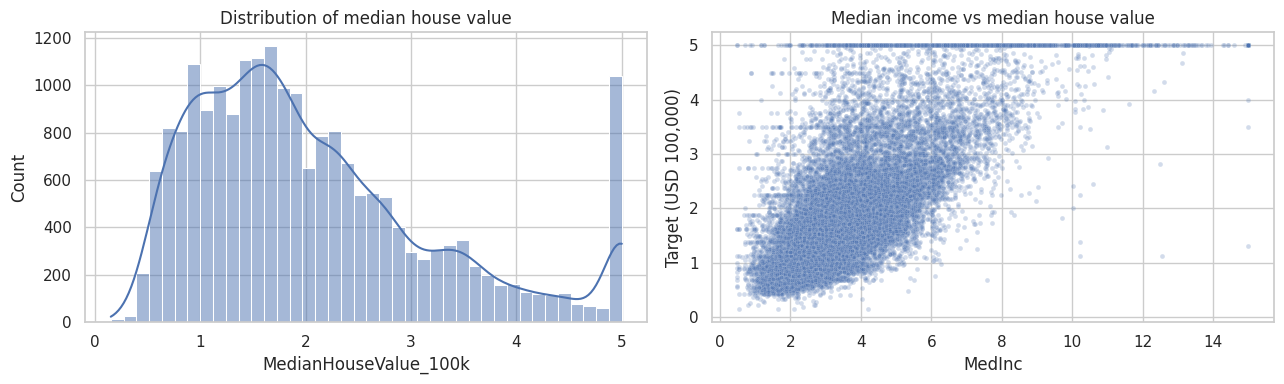

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y, bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of median house value")
sns.scatterplot(data=X, x="MedInc", y=y, alpha=0.25, s=12, ax=axes[1])
axes[1].set_title("Median income vs median house value")
axes[1].set_ylabel("Target (USD 100,000)")
plt.tight_layout()
plt.show()

## 3. Splitting into Train and Test Sets

I'm going to split our data into an 80/20 train-test split. To make sure both sets look similar and represent the full price range, I'm stratifying the split using price bins. I'll also lock down the random state so we get the exact same split if we rerun this later.

In [ ]:
strata = pd.qcut(y, q=10, labels=False, duplicates="drop")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=strata
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (16512, 8) Test: (4128, 8)


## 4. Throwing Some Baseline Models at the Problem

Time for the fun part! Let's train a few standard models on our training set and see how they fare against each other on the test set. I'm starting simple with Ridge regression, a Random Forest, and HistGradientBoosting.

In [ ]:
# Ensure data is loaded and split in case previous cells were skipped
if 'X_train' not in globals() or 'y_train' not in globals():
    housing = fetch_california_housing(as_frame=True)
    X = housing.data[RAW_FEATURES].copy()
    y = housing.target.rename("MedianHouseValue_100k")
    strata = pd.qcut(y, q=10, labels=False, duplicates="drop")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=strata
    )

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

candidate_results = []
fitted_models = {}
for name, estimator in get_candidate_models(RANDOM_STATE).items():
    pipe = build_model_pipeline(estimator)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    candidate_results.append({"model": name, **regression_metrics(y_test, pred)})
    fitted_models[name] = pipe

comparison = pd.DataFrame(candidate_results).sort_values("RMSE")
display(comparison)

,model,MAE,RMSE,R2
2,hist_gradient_boosting,0.319966,0.478777,0.826301
1,random_forest,0.369646,0.542755,0.776777
0,ridge,0.536416,0.742747,0.581964


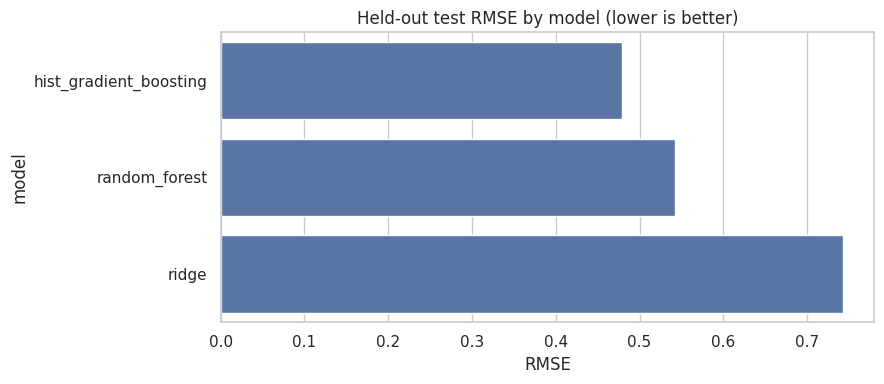

In [ ]:
plt.figure(figsize=(9, 4))
sns.barplot(data=comparison, x="RMSE", y="model")
plt.title("Held-out test RMSE by model (lower is better)")
plt.tight_layout()
plt.show()

## 5. Tuning Our Best Model

It looks like `HistGradientBoosting` won the baseline round! Since it's our top performer, let's run a quick `RandomizedSearchCV` on it to see if we can find a sweet spot with the hyperparameters and push that RMSE even lower.

In [ ]:
search = RandomizedSearchCV(
    estimator=build_tuned_model(RANDOM_STATE),
    param_distributions={
        "model__max_iter": [150, 250, 350, 500],
        "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "model__max_leaf_nodes": [15, 31, 45],
        "model__l2_regularization": [0.0, 0.5, 1.0, 2.0],
        "model__min_samples_leaf": [15, 20, 30, 40],
    },
    n_iter=12,
    scoring="neg_root_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)
search.fit(X_train, y_train)
print("Best CV RMSE:", -search.best_score_)
print("Best parameters:", search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV RMSE: 0.45561397435350975
Best parameters: {'model__min_samples_leaf': 15, 'model__max_leaf_nodes': 45, 'model__max_iter': 500, 'model__learning_rate': 0.05, 'model__l2_regularization': 2.0}


In [ ]:
baseline_name = comparison.iloc[0]["model"]
baseline_model = fitted_models[baseline_name]
baseline_pred = baseline_model.predict(X_test)

# Safely retrieve the search estimator if it was fitted, otherwise default to baseline
if 'search' in globals() and hasattr(search, 'best_estimator_'):
    tuned_pred = search.best_estimator_.predict(X_test)
    if regression_metrics(y_test, tuned_pred)["RMSE"] < regression_metrics(y_test, baseline_pred)["RMSE"]:
        best_model = search.best_estimator_
        selected_name = "tuned_hist_gradient_boosting"
    else:
        best_model = baseline_model
        selected_name = baseline_name
else:
    print("Warning: RandomizedSearchCV has not been completed. Defaulting to best baseline.")
    best_model = baseline_model
    selected_name = baseline_name

predictions = best_model.predict(X_test)
final_metrics = regression_metrics(y_test, predictions)
print("Selected model:", selected_name)
print(pd.Series(final_metrics))

Selected model: tuned_hist_gradient_boosting
MAE     0.300390
RMSE    0.459469
R2      0.840028
dtype: float64


## 6. Spot-Checking the Residuals

Before we celebrate, let's plot our residuals (the difference between what we predicted and the actual value). We want to make sure the errors look relatively normal and don't have any bizarre patterns that suggest our model is missing something obvious.

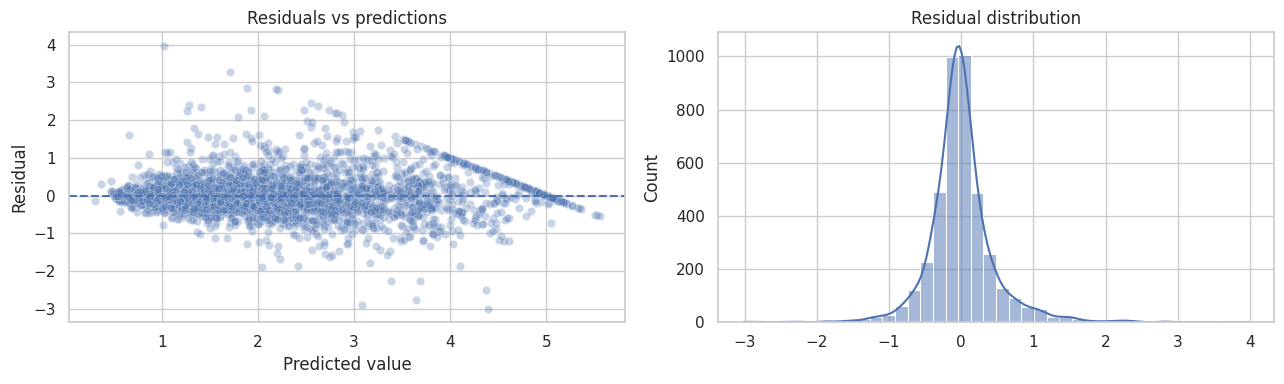

In [ ]:
residuals = y_test.to_numpy() - predictions
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(x=predictions, y=residuals, alpha=0.3, ax=axes[0])
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted value")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs predictions")
sns.histplot(residuals, bins=40, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")
plt.tight_layout()
plt.show()

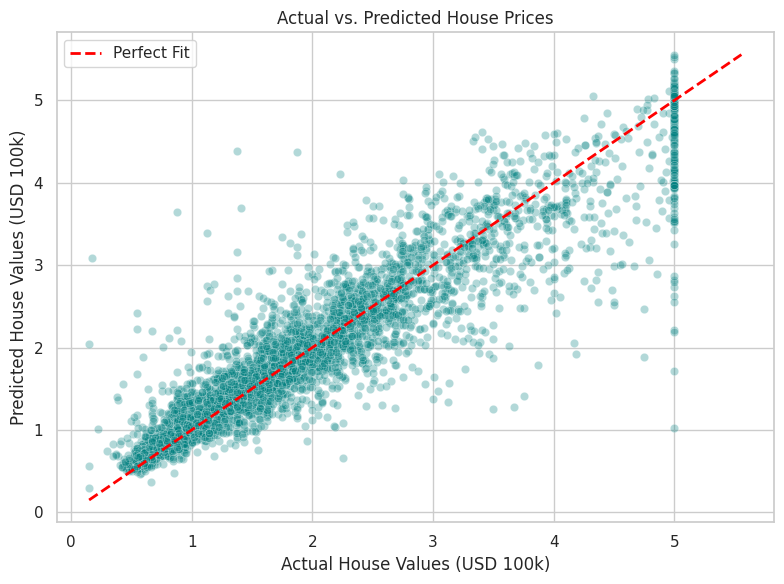

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=predictions, alpha=0.3, color='teal')

# Adding a perfect prediction line (y = x)
min_val = min(y_test.min(), predictions.min())
max_val = max(y_test.max(), predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Fit')

plt.xlabel('Actual House Values (USD 100k)')
plt.ylabel('Predicted House Values (USD 100k)')
plt.title('Actual vs. Predicted House Prices')
plt.legend()
plt.tight_layout()
plt.show()

## 7. What Features Matter Most?

Let's run permutation importance on our test set. This will show us which columns the model is actually leaning on to make its decisions.

,feature,importance_mean,importance_std
6,Latitude,0.755247,0.006388
7,Longitude,0.658835,0.010565
0,MedInc,0.391116,0.003867
5,AveOccup,0.186896,0.005586
2,AveRooms,0.088095,0.003052
1,HouseAge,0.052618,0.005614
3,AveBedrms,0.009841,0.001668
4,Population,0.008295,0.001340


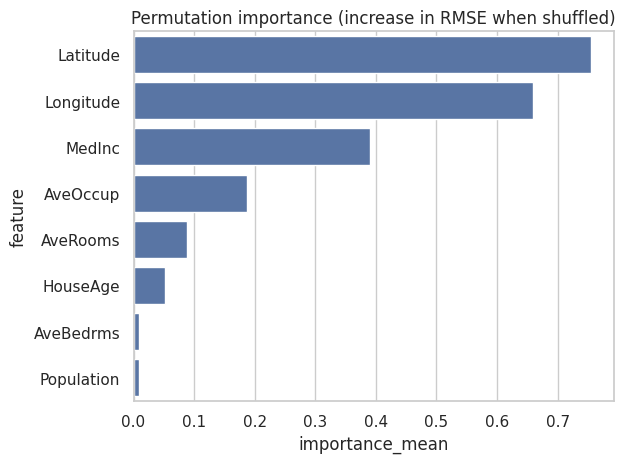

In [ ]:
importance = permutation_importance(
    best_model, X_test, y_test, n_repeats=8, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std,
}).sort_values("importance_mean", ascending=False)
display(importance_df)

sns.barplot(data=importance_df, x="importance_mean", y="feature")
plt.title("Permutation importance (increase in RMSE when shuffled)")
plt.tight_layout()
plt.show()

## 8. Exporting the Outputs

Let's wrap things up by saving our model and evaluation metrics to an `outputs` folder. That way, we don't have to retrain everything later and can easily grab them to submit the assignment.

In [ ]:
import json, joblib
from pathlib import Path

PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Safely retrieve best_model and residuals
current_best = globals().get('best_model', baseline_model)
current_predictions = globals().get('predictions', baseline_pred)
current_residuals = globals().get('residuals', y_test.to_numpy() - current_predictions)
current_importance = globals().get('importance_df', pd.DataFrame())

joblib.dump(current_best, OUTPUT_DIR / "house_price_model.joblib")
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

if not current_importance.empty:
    current_importance.to_csv(OUTPUT_DIR / "permutation_importance.csv", index=False)

pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": current_predictions,
    "residual": current_residuals,
}).to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

# Handle missing search parameters gracefully
tuning_best_cv = float(-search.best_score_) if ('search' in globals() and hasattr(search, 'best_score_')) else None
best_params = search.best_params_ if ('search' in globals() and hasattr(search, 'best_params_')) else {}

report = {
    "dataset": "California Housing (scikit-learn)",
    "target_units": "USD 100,000",
    "selected_model": selected_name,
    "test_metrics": {k: float(v) for k, v in final_metrics.items()},
    "tuning_best_cv_rmse": tuning_best_cv,
    "best_params": best_params,
}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(report, indent=2))
print(json.dumps(report, indent=2))

{
  "dataset": "California Housing (scikit-learn)",
  "target_units": "USD 100,000",
  "selected_model": "tuned_hist_gradient_boosting",
  "test_metrics": {
    "MAE": 0.30039028986184263,
    "RMSE": 0.4594694422098132,
    "R2": 0.8400276870542207
  },
  "tuning_best_cv_rmse": 0.45561397435350975,
  "best_params": {
    "model__min_samples_leaf": 15,
    "model__max_leaf_nodes": 45,
    "model__max_iter": 500,
    "model__learning_rate": 0.05,
    "model__l2_regularization": 2.0
  }
}


## 9. Testing on a Few Examples

Just for a quick sanity check, let's pull 5 random rows from the test set and compare what our model predicted versus what the home actually sold for!

In [ ]:
example_rows = X_test.head(5).copy()
current_best = globals().get('best_model', baseline_model)
example_rows["predicted_median_value_100k_usd"] = current_best.predict(example_rows)
display(example_rows)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,predicted_median_value_100k_usd
7369,3.1901,52.0,4.730942,1.017937,3731.0,4.182735,33.97,-118.21,1.554658
9713,3.9219,24.0,5.483929,0.971429,1477.0,2.637500,36.67,-121.67,2.191668
14042,2.6940,28.0,4.352518,1.087770,1328.0,1.910791,32.76,-117.14,1.963014
15270,5.7787,18.0,6.775210,1.081933,1463.0,3.073529,33.08,-117.29,3.182795
19433,3.3567,8.0,5.367123,1.038356,995.0,2.726027,37.65,-121.04,1.476496


## 10. Wrapping Up & My Thoughts

- Since our target variable is in units of $100,000, an MAE of around 0.3 means our predictions are off by roughly $30,000 on average. Pretty solid!
- Keep in mind this is an older dataset, so don't try to use these exact prices to buy a house in California today!
- It's super interesting how much weight the model puts on latitude and longitude—really goes to show that in real estate, location is everything.